# Treino, validação e teste por período

Os limites foram fixados por calendário, sem procurar o corte que maximiza as métricas. Nenhum dia atravessa conjuntos. Este notebook não lê rótulos do teste.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)


In [2]:
from ml.experiment import prepare_split
features = prepare_split()
summary = pd.read_csv(REPORTS / "periodos.csv")
display(style_table(summary))


periodo,inicio,fim,registros,parceiros,sem_historico
treino,2024-01-01,2024-12-30,17692,156,233
validacao,2025-01-01,2025-06-30,11077,161,42
teste,2025-07-01,2025-12-30,11023,160,27


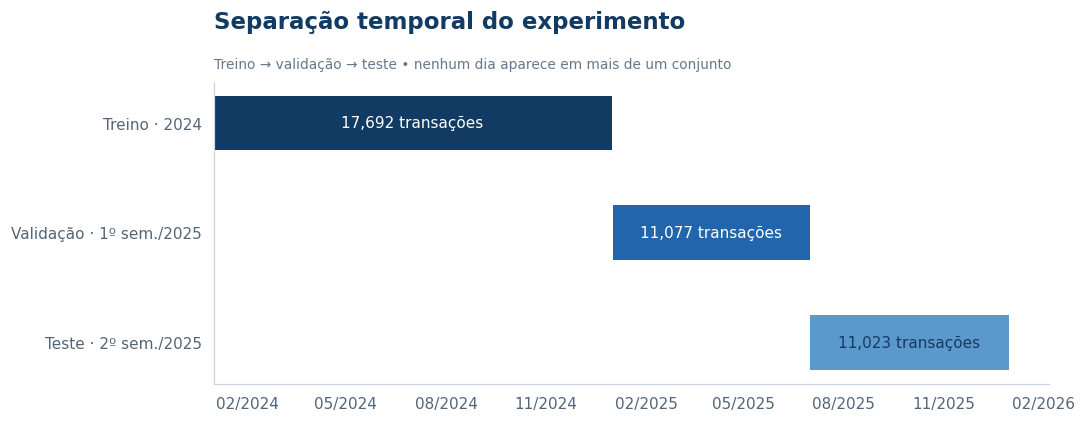

In [3]:
from ml.diagnostics import split_figure
figure = split_figure(summary)
save_figure(figure, "periodos", "experimento")
display(figure)
plt.close(figure)


## Como o tempo é respeitado

**Treino:** 01/01–31/12/2024. **Validação:** 01/01–30/06/2025. **Teste:** 01/07–31/12/2025.

O histórico de cada exemplo contém apenas dias anteriores. No protocolo de scoring sequencial, uma transação observada na segunda-feira pode compor o contexto de terça-feira, mesmo no teste; seu rótulo não é utilizado. O modelo não é retreinado durante validação ou teste. Isso avalia monitoramento contínuo, não uma previsão de todo o semestre feita na véspera.

Os mesmos parceiros podem aparecer nos três períodos. A avaliação mede avanço no tempo, não generalização a uma população inteiramente nova de parceiros.

In [4]:
assert features.id_transacao_natural.is_unique
periods = {name: group for name, group in features.groupby("periodo")}
assert periods["treino"].data.max() < periods["validacao"].data.min()
assert periods["validacao"].data.max() < periods["teste"].data.min()
print("Verificado: chaves únicas, períodos disjuntos e ordem temporal preservada.")


Verificado: chaves únicas, períodos disjuntos e ordem temporal preservada.
